# Uji Validitas dan Reliabilitas Instrumen Kuesioner
**Mata Kuliah:** Statistika Probabilitas | **Alat:** Python di Google Colab

**Topik:** Penggunaan AI, kebiasaan digital, prokrastinasi akademik, dan respon emosional mahasiswa (data kelas 3 TI A)

# 1. Persiapan Lingkungan dan Impor Pustaka

In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
from google.colab import files


import matplotlib.pyplot as plt

# 2. Unggah Berkas Data
Unggah file `Blank_Quiz__Responses_.xlsx` (ekspor Google Forms yang masih memuat baris judul kolom).

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


# 3. Membaca Data dan Memisahkan Butir
Data berisi semua kelas, sehingga disaring hanya **3 TI A**. Ada 6 kolom demografi (Timestamp, Score, Kelas, Jenis Kelamin, dan 2 kolom jumlah platform AI). Kolom *Durasi penggunaan gadget* bukan skala Likert, sehingga dikeluarkan dari butir (hanya kolom berformat `Dimensi [pernyataan]` yang dipakai).

In [3]:
JUMLAH_KOLOM_DEMOGRAFI = 6  # ubah sesuai jumlah kolom demografi pada data

df = pd.read_excel(nama_file)
df = df[df["Kelas"].astype(str).str.strip() == "3 TI A"].reset_index(drop=True)

butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
# buang kolom non-Likert (durasi gadget): hanya ambil kolom berformat "Dimensi [pernyataan]"
butir = butir[[k for k in butir.columns if re.match(r"^(.*?) \[", k)]]

print("Jumlah responden :", len(df))
print("Jumlah butir :", butir.shape[1])
print("Data kosong :", int(butir.isna().sum().sum()))

Jumlah responden : 39
Jumlah butir : 29
Data kosong : 0


**Pertanyaan pemantik:** Berapa jumlah responden (n)? Mengapa data kosong harus 0?

**Jawab:** n = 39 responden. Data kosong harus 0 karena nilai kosong membuat skor total dan korelasi tidak dapat dihitung (atau menjadi bias bila baris dibuang), sehingga r hitung dan alpha tidak akurat.

# 4. Mengubah Jawaban Likert Menjadi Angka

In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_1715/4148410009.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,3,4,5,3,4,5,5,4,3,3,...,2,3,3,3,3,4,4,5,4,5
1,4,5,4,4,2,5,4,3,4,2,...,3,4,2,3,4,1,2,3,4,5
2,4,4,4,4,2,4,5,4,3,2,...,1,4,5,4,5,4,3,4,5,5
3,5,4,2,1,1,5,5,1,2,3,...,1,5,4,4,5,5,1,5,3,1
4,4,4,5,3,4,5,4,5,4,3,...,2,1,1,1,1,4,4,5,1,5


# 5. Mengelompokkan Butir per Dimensi

In [5]:
dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik.: 4 butir
Rsspon emosional: 5 butir


**Pertanyaan pemantik:** Apakah jumlah dimensi dan butir sudah sesuai rancangan?

**Jawab:** Ya. Terdapat 5 dimensi: Penggunaan AI (7 butir), Aspek Psikologis (7), Kebiasaan Teknologi Digital (6), Prokrastinasi Akademik (4), dan Respon Emosional (5), total 29 butir.

# 6. Uji Validitas (Korelasi Pearson Butir-Total)

In [6]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.538,0.228,0.0004,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.645,0.377,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.495,0.213,0.0014,Valid


**Pertanyaan pemantik:** Adakah butir yang lolos berdasarkan r hitung tetapi corrected r-nya jauh lebih rendah? Mengapa selisih lebih besar pada dimensi dengan butir sedikit?

**Jawab:** Ada, misalnya PA5 (r = 0,515 tetapi corrected r = 0,126) dan RE3 (0,467 menjadi 0,111). Pada r hitung biasa, butir ikut menyumbang pada skor total sehingga korelasinya terdongkrak (*part-whole overlap*). Pada dimensi dengan butir sedikit, sumbangan satu butir terhadap total jauh lebih besar, sehingga penggelembungan itu lebih besar dan selisih r hitung dengan corrected r pun melebar.

# 7. Uji Reliabilitas (Cronbach's Alpha)

In [7]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a), })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik.,4,0.863,Baik
4,Rsspon emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.312


**Pertanyaan pemantik:** Mengapa α cenderung naik jika jumlah butir bertambah, padahal kualitas butir tidak berubah?

**Jawab:** Rumus α memuat faktor k/(k−1) dan rasio jumlah varians butir terhadap varians total. Semakin banyak butir, kovarians antar butir yang dijumlahkan ke varians total semakin besar dibanding jumlah varians butir tunggal, sehingga α naik walau kualitas tiap butir sama. Karena itu α tinggi pada dimensi yang butirnya banyak belum tentu berarti butirnya bagus.

# 8. Analisis Deskriptif per Dimensi (untuk laporan)
Menghitung rerata, simpangan baku, skewness, dan kurtosis skor total dimensi, serta grafik komposisi jawaban.

,Dimensi,Rerata,Std. deviasi,Skewness,Kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,27.28,3.017,-0.425,1.612
1,Aspek Psikologis penggunaan AI pada tugas atau...,21.92,3.737,0.248,-0.752
2,Kebiasaan penggunaan teknologi digital,16.69,3.722,-0.255,-0.212
3,Prokrastinasi akademik.,11.05,4.065,0.236,-0.553
4,Rsspon emosional,19.38,3.322,-1.524,3.948


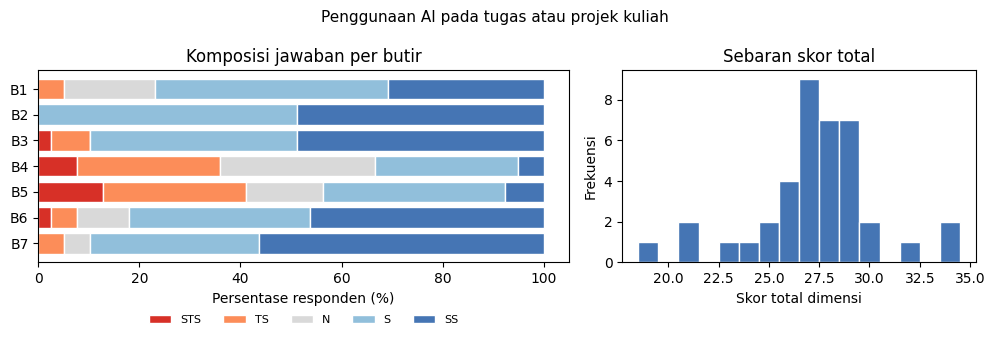

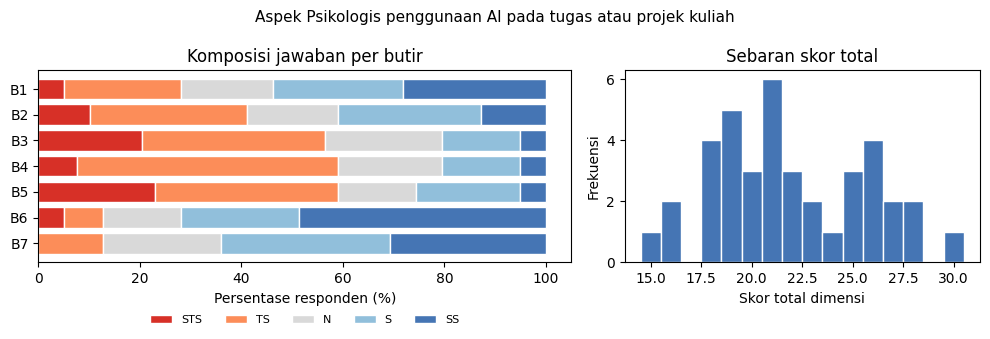

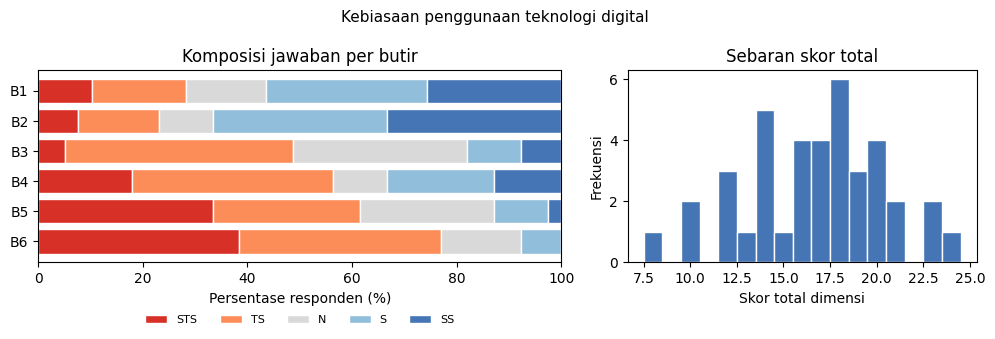

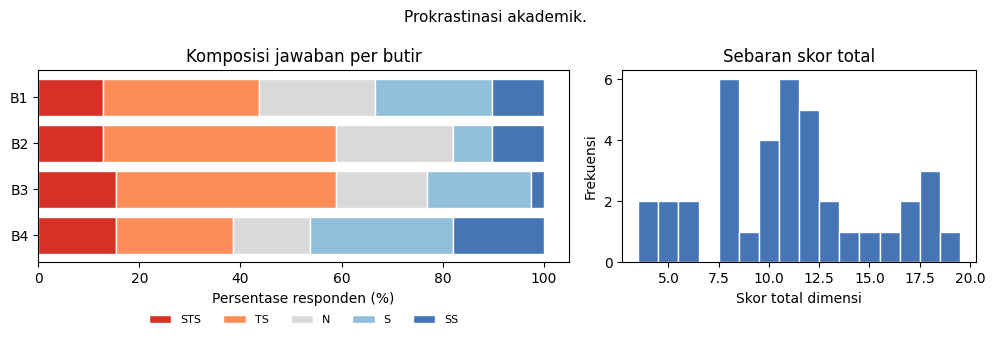

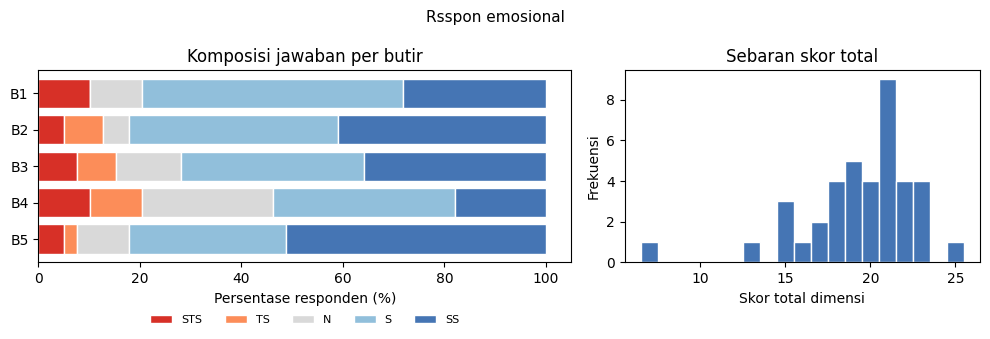

In [8]:
deskriptif = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    deskriptif.append({
        "Dimensi": nama,
        "Rerata": round(total.mean(), 2),
        "Std. deviasi": round(total.std(ddof=1), 3),
        "Skewness": round(stats.skew(total, bias=False), 3),
        "Kurtosis": round(stats.kurtosis(total, bias=False), 3),
    })
display(pd.DataFrame(deskriptif))

warna = ["#d73027", "#fc8d59", "#d9d9d9", "#91bfdb", "#4575b4"]
label = ["STS", "TS", "N", "S", "SS"]
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    pct = np.array([[(x[k] == v).mean() * 100 for v in range(1, 6)] for k in daftar])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
    kiri = np.zeros(len(daftar))
    for v in range(5):
        ax[0].barh(range(len(daftar)), pct[:, v], left=kiri, color=warna[v], label=label[v], edgecolor="white")
        kiri += pct[:, v]
    ax[0].set_yticks(range(len(daftar)))
    ax[0].set_yticklabels([f"B{i}" for i in range(1, len(daftar) + 1)])
    ax[0].invert_yaxis()
    ax[0].set_xlabel("Persentase responden (%)")
    ax[0].set_title("Komposisi jawaban per butir")
    ax[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
    ax[1].hist(total, bins=range(int(total.min()), int(total.max()) + 2), color="#4575b4", edgecolor="white", align="left")
    ax[1].set_xlabel("Skor total dimensi")
    ax[1].set_ylabel("Frekuensi")
    ax[1].set_title("Sebaran skor total")
    fig.suptitle(nama, fontsize=11)
    plt.tight_layout()
    plt.show()

# 9. Menggabungkan dan Mengunduh Hasil

In [9]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 10. Mini Challenge 1: Interpretasi Butir Tidak Valid
Sebutkan butir yang tidak valid beserta r hitung dan r tabel (r tabel = 0,316).

In [10]:
tabel_validitas[tabel_validitas["Keterangan"] == "Tidak valid"]

,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972,Tidak valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237,Tidak valid
12,Aspek Psikologis penggunaan AI pada tugas atau...,B6,0.129,-0.191,0.4329,Tidak valid
13,Aspek Psikologis penggunaan AI pada tugas atau...,B7,0.127,-0.146,0.4406,Tidak valid
18,Kebiasaan penggunaan teknologi digital,B5,0.285,-0.013,0.0790,Tidak valid


Terdapat **5 butir tidak valid** dari 29 butir (r hitung < r tabel 0,316):

| Butir | Pernyataan (ringkas) | r hitung | r tabel |
|---|---|---|---|
| PA2 | Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkul… | 0.269 | 0,316 |
| PA7 | Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggu… | 0.016 | 0,316 |
| AP6 | Penggunaan AI membuat saya lebih tertarik untuk mempelajari materi perkulia… | 0.129 | 0,316 |
| AP7 | Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah … | 0.127 | 0,316 |
| KD5 | Saya tidak mengkhawatirkan hasil yang diberikan AI | 0.285 | 0,316 |

**Dugaan penyebab:** (1) *Arah pernyataan berbeda.* PA7 (memeriksa kembali jawaban AI), AP6 (tertarik belajar karena AI), dan AP7 (tetap yakin pada kemampuan sendiri) bukan pernyataan ketergantungan, padahal butir lain pada dimensi yang sama mengukur ketergantungan, sehingga berbeda arah dan konstruk dengan skor total, sehingga korelasinya mendekati nol atau negatif. (2) *Varians rendah.* PA2 hanya bervariasi sedikit (jawaban kebanyakan sama), sehingga korelasi sulit tinggi. (3) *Ambigu/berbeda konstruk.* KD5 tentang "tidak mengkhawatirkan hasil AI" berbeda fokus dari butir KD lain yang membahas gangguan saat mengerjakan tugas.

# 11. Mini Challenge 2: Perbandingan Kriteria (r hitung vs corrected r ≥ 0,30)

In [11]:
valid_r = (tabel_validitas["r hitung"] > r_tabel).sum()
valid_rc = (tabel_validitas["Corrected r"] >= 0.30).sum()
print("Valid berdasarkan r hitung > r tabel :", valid_r, "dari", len(tabel_validitas))
print("Valid berdasarkan corrected r >= 0,30 :", valid_rc, "dari", len(tabel_validitas))

Valid berdasarkan r hitung > r tabel : 24 dari 29
Valid berdasarkan corrected r >= 0,30 : 13 dari 29


**Hasil:** 24 butir valid menurut r hitung, tetapi hanya **13 butir** menurut corrected r ≥ 0,30 (selisih 11 butir).

**Penjelasan:** r hitung biasa mengorelasikan butir dengan total yang masih memuat butir itu sendiri, sehingga korelasi menjadi terlalu optimistis. Corrected r mengeluarkan butir dari total, sehingga ukurannya lebih ketat dan lebih jujur. Selisih besar menunjukkan banyak butir yang tampak valid hanya karena ikut menyusun total, bukan karena benar-benar searah dengan butir lain.

# 12. Mini Challenge 3: Perbaikan Instrumen (buang butir tidak valid, hitung ulang alpha)
Butir yang dibuang: **B7** pada dimensi *Penggunaan AI* (r hitung 0,016; alpha jika dihapus 0,513 > alpha dimensi 0,370).

In [12]:
kunci = "Penggunaan AI pada tugas atau projek kuliah"
x_awal = num[dimensi[kunci]]
x_baru = x_awal.drop(columns=dimensi[kunci][6])   # buang B7

print(f"Alpha sebelum : {cronbach_alpha(x_awal):.3f} ({kategori(cronbach_alpha(x_awal))})")
print(f"Alpha sesudah : {cronbach_alpha(x_baru):.3f} ({kategori(cronbach_alpha(x_baru))})")

Alpha sebelum : 0.370 (Tidak reliabel)
Alpha sesudah : 0.513 (Tidak reliabel)


**Hasil:** alpha dimensi Penggunaan AI naik dari 0,370 menjadi **0,513**, tetapi masih di bawah 0,70 (tidak reliabel). Membuang satu butir bermasalah membantu, namun belum cukup; dimensi masih perlu perbaikan butir lain atau penambahan butir yang relevan.

# 13. Mini Challenge 4: Pengaruh Ukuran Sampel (n = 20)

In [13]:
sampel = num.sample(20, random_state=1)
n2 = len(sampel)
t2 = stats.t.ppf(0.975, n2 - 2)
r_tabel2 = t2 / np.sqrt((n2 - 2) + t2**2)
print(f"n = {n2} | r tabel = {r_tabel2:.3f}")

jumlah_valid = 0
for nama, daftar in dimensi.items():
    xs = sampel[daftar]
    tot = xs.sum(axis=1)
    for kolom in daftar:
        if stats.pearsonr(xs[kolom], tot)[0] > r_tabel2:
            jumlah_valid += 1
print("Butir valid:", jumlah_valid, "dari", num.shape[1])

n = 20 | r tabel = 0.444
Butir valid: 23 dari 29


**Hasil:** dengan n = 20, r tabel naik dari 0,316 menjadi **0,444** (sampel lebih kecil membutuhkan korelasi lebih besar agar signifikan). Jumlah butir valid dengan subset ini adalah 23 dari 29, sedikit lebih sedikit daripada n = 39 (24 butir). Subset kecil juga membuat hasil lebih tidak stabil.

# 14. Refleksi
**Mengapa instrumen yang reliabel belum tentu valid? Berikan contoh sederhana.**

Reliabilitas hanya menunjukkan **konsistensi** hasil ukur, sedangkan validitas menunjukkan apakah alat **mengukur hal yang benar**. Instrumen bisa konsisten tetapi konsisten mengukur hal yang salah. Contoh: timbangan yang selalu menunjukkan angka 2 kg lebih berat. Hasilnya konsisten (reliabel) pada setiap penimbangan, tetapi tidak akurat (tidak valid). Pada kuesioner, empat butir yang semuanya bertanya "seberapa sering Anda membuka media sosial" bisa sangat konsisten (alpha tinggi), tetapi tidak valid bila dipakai untuk mengukur prokrastinasi akademik. Sebaliknya, instrumen yang valid secara isi biasanya perlu reliabel; reliabilitas adalah syarat perlu, bukan syarat cukup, bagi validitas.